In [1]:
# importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [2]:
# Load dataset
file_path = "loan.xlsx"
df = pd.read_excel(file_path)
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [22]:
# understanding the dataset
print("Dataset loaded successfully.")
print("Original Rows:", df.shape[0])
print("Original Columns:", df.shape[1])

print("\nFirst few rows of the dataset:")
display(df.head())

Dataset loaded successfully.
Original Rows: 39717
Original Columns: 53

First few rows of the dataset:


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type
0,1077501,1296599,5000,5000,4975.0,36 months,0.1065,162.87,B,B2,...,0.00,0.00,2015-01-01,171.62,NaT,2016-05-01,0.0,NaN,1,INDIVIDUAL
1,1077430,1314167,2500,2500,2500.0,60 months,0.1527,59.83,C,C4,...,117.08,1.11,2013-04-01,119.66,NaT,2013-09-01,0.0,NaN,1,INDIVIDUAL
2,1077175,1313524,2400,2400,2400.0,36 months,0.1596,84.33,C,C5,...,0.00,0.00,2014-06-01,649.91,NaT,2016-05-01,0.0,NaN,1,INDIVIDUAL
3,1076863,1277178,10000,10000,10000.0,36 months,0.1349,339.31,C,C1,...,0.00,0.00,2015-01-01,357.48,NaT,2016-04-01,0.0,NaN,1,INDIVIDUAL
4,1075358,1311748,3000,3000,3000.0,60 months,0.1269,67.79,B,B5,...,0.00,0.00,2016-05-01,67.79,2016-06-01,2016-05-01,0.0,NaN,1,INDIVIDUAL


In [23]:
# summary of the dataset
print("\nSummary of the dataset:")
display(df.info())


Summary of the dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39717 entries, 0 to 39716
Data columns (total 53 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   id                           39717 non-null  int64         
 1   member_id                    39717 non-null  int64         
 2   loan_amnt                    39717 non-null  int64         
 3   funded_amnt                  39717 non-null  int64         
 4   funded_amnt_inv              39717 non-null  float64       
 5   term                         39717 non-null  object        
 6   int_rate                     39717 non-null  float64       
 7   installment                  39717 non-null  float64       
 8   grade                        39717 non-null  object        
 9   sub_grade                    39717 non-null  object        
 10  emp_title                    37258 non-null  object        
 11  emp_length      

None

In [24]:
# Filtering only columns needed for the project
selected_columns = [
    "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade",
    "emp_length", "home_ownership", "annual_inc", "verification_status",
    "purpose", "dti", "delinq_2yrs", "inq_last_6mths", "open_acc",
    "pub_rec", "revol_bal", "revol_util", "total_acc", "loan_status"
]
df_clean = df[selected_columns].copy()

# Display the filtered dataset summary and head
print("Filtered dataset with selected columns:")
display(df_clean.head())

Filtered dataset with selected columns:


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,loan_status
0,5000,36 months,0.1065,162.87,B,B2,10+ years,RENT,24000.0,Verified,credit_card,27.65,0,1,3,0,13648,0.837,9,Fully Paid
1,2500,60 months,0.1527,59.83,C,C4,< 1 year,RENT,30000.0,Source Verified,car,1.00,0,5,3,0,1687,0.094,4,Charged Off
2,2400,36 months,0.1596,84.33,C,C5,10+ years,RENT,12252.0,Not Verified,small_business,8.72,0,2,2,0,2956,0.985,10,Fully Paid
3,10000,36 months,0.1349,339.31,C,C1,10+ years,RENT,49200.0,Source Verified,other,20.00,0,1,10,0,5598,0.210,37,Fully Paid
4,3000,60 months,0.1269,67.79,B,B5,1 year,RENT,80000.0,Source Verified,other,17.94,0,0,15,0,27783,0.539,38,Current


In [25]:
# Calculate number of duplicate records in the clean dataset
duplicate_count = df_clean.duplicated().sum()

# Display the count of duplicate records
print("Number of duplicate records in df_clean:", duplicate_count)

Number of duplicate records in df_clean: 0


In [26]:
# Cleaning Text Columns by stripping leading/trailing whitespaces
text_columns = ['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership',
       'verification_status', 'purpose', 'loan_status']

for col in text_columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# Cleaning Numeric Columns and forcing non-numeric values to NaN
numeric_columns = [
    "loan_amnt", "int_rate", "installment", "annual_inc", "dti",
    "delinq_2yrs", "inq_last_6mths", "open_acc", "pub_rec",
    "revol_bal", "revol_util", "total_acc"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Display dataset after text and numeric cleaning
print("Dataset after cleaning text and numeric columns (first 5 rows):")
display(df_clean.head())

Dataset after cleaning text and numeric columns (first 5 rows):


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,loan_status
0,5000,36 months,0.1065,162.87,B,B2,10+ years,RENT,24000.0,Verified,credit_card,27.65,0,1,3,0,13648,0.837,9,Fully Paid
1,2500,60 months,0.1527,59.83,C,C4,< 1 year,RENT,30000.0,Source Verified,car,1.00,0,5,3,0,1687,0.094,4,Charged Off
2,2400,36 months,0.1596,84.33,C,C5,10+ years,RENT,12252.0,Not Verified,small_business,8.72,0,2,2,0,2956,0.985,10,Fully Paid
3,10000,36 months,0.1349,339.31,C,C1,10+ years,RENT,49200.0,Source Verified,other,20.00,0,1,10,0,5598,0.210,37,Fully Paid
4,3000,60 months,0.1269,67.79,B,B5,1 year,RENT,80000.0,Source Verified,other,17.94,0,0,15,0,27783,0.539,38,Current


In [27]:
# Display no of missing values
missing_values = df_clean.isnull().sum().sort_values(ascending=False)
print("\ncolumns with missing values:")
print(missing_values[missing_values > 0])


columns with missing values:
revol_util    50
dtype: int64


In [28]:
# Handle Missing Values
for col in numeric_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

categorical_columns = df_clean.select_dtypes(include="object").columns
for col in categorical_columns:
    mode_value = df_clean[col].mode(dropna=True)
    if len(mode_value) > 0:
        df_clean[col] = df_clean[col].fillna(mode_value.iloc[0])
    else:
        df_clean[col] = df_clean[col].fillna("Unknown")

print("\nAfter handling missing values:")
print(df_clean)



After handling missing values:
       loan_amnt       term  int_rate  installment grade sub_grade emp_length  \
0           5000  36 months    0.1065       162.87     B        B2  10+ years   
1           2500  60 months    0.1527        59.83     C        C4   < 1 year   
2           2400  36 months    0.1596        84.33     C        C5  10+ years   
3          10000  36 months    0.1349       339.31     C        C1  10+ years   
4           3000  60 months    0.1269        67.79     B        B5     1 year   
...          ...        ...       ...          ...   ...       ...        ...   
39712       2500  36 months    0.0807        78.42     A        A4    4 years   
39713       8500  36 months    0.1028       275.38     C        C1    3 years   
39714       5000  36 months    0.0807       156.84     A        A4   < 1 year   
39715       5000  36 months    0.0743       155.38     A        A2   < 1 year   
39716       7500  36 months    0.1375       255.43     E        E2   < 1 year

In [29]:
# 3.1 Encoding - Label Encoding
# Convert categorical loan status and grade to numerical labels
loan_status_encoder = LabelEncoder()
df_clean["loan_status_encoded"] = loan_status_encoder.fit_transform(df_clean["loan_status"])

grade_encoder = LabelEncoder()
df_clean["grade_encoded"] = grade_encoder.fit_transform(df_clean["grade"])

print("Label encoding completed.")
display(df_clean[["loan_status", "loan_status_encoded", "grade", "grade_encoded"]].head())

Label encoding completed.


,loan_status,loan_status_encoded,grade,grade_encoded
0,Fully Paid,2,B,1
1,Charged Off,0,C,2
2,Fully Paid,2,C,2
3,Fully Paid,2,C,2
4,Current,1,B,1


In [30]:
# 3.2 Encoding - One-Hot Encoding
# Apply one-hot encoding to home_ownership, verification_status, and purpose columns
one_hot_columns = ["home_ownership", "verification_status", "purpose"]
df_encoded = pd.get_dummies(df_clean, columns=one_hot_columns, dtype=int)

print("One-hot encoding completed. Encoded dataset shape:", df_encoded.shape)
display(df_encoded.head())

One-hot encoding completed. Encoded dataset shape: (39717, 41)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,annual_inc,dti,delinq_2yrs,...,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding
0,5000,36 months,0.1065,162.87,B,B2,10+ years,24000.0,27.65,0,...,0,0,0,0,0,0,0,0,0,0
1,2500,60 months,0.1527,59.83,C,C4,< 1 year,30000.0,1.00,0,...,0,0,0,0,0,0,0,0,0,0
2,2400,36 months,0.1596,84.33,C,C5,10+ years,12252.0,8.72,0,...,0,0,0,0,0,0,0,1,0,0
3,10000,36 months,0.1349,339.31,C,C1,10+ years,49200.0,20.00,0,...,0,0,0,0,0,1,0,0,0,0
4,3000,60 months,0.1269,67.79,B,B5,1 year,80000.0,17.94,0,...,0,0,0,0,0,1,0,0,0,0


In [31]:
# 3.3 Feature Scaling
# Standardize numerical features using StandardScaler
scaler = StandardScaler()
df_scaled = df_encoded.copy()
df_scaled[numeric_columns] = scaler.fit_transform(df_encoded[numeric_columns])

print("Feature scaling completed. Scaled dataset shape:", df_scaled.shape)
display(df_scaled.head())

Feature scaling completed. Scaled dataset shape: (39717, 41)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,annual_inc,dti,delinq_2yrs,...,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding
0,-0.834088,36 months,-0.368123,-0.774119,B,B2,10+ years,-0.704920,2.146418,-0.297906,...,0,0,0,0,0,0,0,0,0,0
1,-1.169363,60 months,0.872219,-1.267435,C,C4,< 1 year,-0.610866,-1.843994,-0.297906,...,0,0,0,0,0,0,0,0,0,0
2,-1.182774,36 months,1.057465,-1.150138,C,C5,10+ years,-0.889078,-0.688047,-0.297906,...,0,0,0,0,0,0,0,1,0,0
3,-0.163539,36 months,0.394338,0.070608,C,C1,10+ years,-0.309892,1.000952,-0.297906,...,0,0,0,0,0,1,0,0,0,0
4,-1.102308,60 months,0.179561,-1.229325,B,B5,1 year,0.172920,0.692500,-0.297906,...,0,0,0,0,0,1,0,0,0,0


In [32]:
# 4.1 Statistical Summary of Numerical Features
# Display descriptive statistics for all selected numeric columns
print("Summary Statistics of Numerical Features:")
display(df_clean[numeric_columns].describe().T)

Summary Statistics of Numerical Features:


,count,mean,std,min,25%,50%,75%,max
loan_amnt,39717.0,11219.443815,7456.670694,500.0000,5500.0000,10000.0000,15000.0000,3.500000e+04
int_rate,39717.0,0.120212,0.037248,0.0542,0.0925,0.1186,0.1459,2.459000e-01
installment,39717.0,324.561922,208.874874,15.6900,167.0200,280.2200,430.7800,1.305190e+03
annual_inc,39717.0,68968.926377,63793.765790,4000.0000,40404.0000,59000.0000,82300.0000,6.000000e+06
dti,39717.0,13.315130,6.678594,0.0000,8.1700,13.4000,18.6000,2.999000e+01
delinq_2yrs,39717.0,0.146512,0.491812,0.0000,0.0000,0.0000,0.0000,1.100000e+01
inq_last_6mths,39717.0,0.869200,1.070219,0.0000,0.0000,1.0000,1.0000,8.000000e+00
open_acc,39717.0,9.294408,4.400282,2.0000,6.0000,9.0000,12.0000,4.400000e+01
pub_rec,39717.0,0.055065,0.237200,0.0000,0.0000,0.0000,0.0000,4.000000e+00
revol_bal,39717.0,13382.528086,15885.016641,0.0000,3703.0000,8850.0000,17058.0000,1.495880e+05


In [33]:
# 4.2 Loan Status Distribution Analysis
# Calculate and print the percentage distribution of loan statuses
loan_status_percentage = (df_clean["loan_status"].value_counts(normalize=True) * 100).round(2)
print("Loan Status Percentage Distribution:")
display(loan_status_percentage)

Loan Status Percentage Distribution:


,proportion
loan_status,
Fully Paid,82.96
Charged Off,14.17
Current,2.87


In [34]:
# 4.3 Average Loan Amount by Status
# Calculate and print the average loan amount requested for each loan status category
average_loan = df_clean.groupby("loan_status")["loan_amnt"].mean().sort_values(ascending=False)
print("Average Loan Amount by Status:")
display(average_loan)

Average Loan Amount by Status:


,loan_amnt
loan_status,
Current,17053.991228
Charged Off,12104.385108
Fully Paid,10866.455994


In [35]:
# 4.4 Correlation Analysis
# Compute the correlation matrix for numerical features
correlation_matrix = df_clean[numeric_columns].corr()
print("Correlation Matrix of Numeric Features:")
display(correlation_matrix)

Correlation Matrix of Numeric Features:


,loan_amnt,int_rate,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc
loan_amnt,1.000000,0.309415,0.930288,0.271149,0.066439,-0.031864,0.009229,0.177168,-0.051236,0.317597,0.066089,0.256442
int_rate,0.309415,1.000000,0.282703,0.053185,0.111162,0.157916,0.133013,0.010395,0.097208,0.097100,0.466773,-0.043570
installment,0.930288,0.282703,1.000000,0.270874,0.054186,-0.019657,0.009722,0.172812,-0.046532,0.312679,0.095411,0.230824
annual_inc,0.271149,0.053185,0.270874,1.000000,-0.122732,0.023083,0.033908,0.158200,-0.018689,0.279961,0.017906,0.235771
dti,0.066439,0.111162,0.054186,-0.122732,1.000000,-0.034452,0.001405,0.288045,-0.004621,0.228743,0.277700,0.229881
delinq_2yrs,-0.031864,0.157916,-0.019657,0.023083,-0.034452,1.000000,0.008091,0.011656,0.007463,-0.055125,-0.043048,0.067892
inq_last_6mths,0.009229,0.133013,0.009722,0.033908,0.001405,0.008091,1.000000,0.091713,0.024802,-0.022381,-0.068555,0.111499
open_acc,0.177168,0.010395,0.172812,0.158200,0.288045,0.011656,0.091713,1.000000,0.000172,0.288964,-0.089827,0.686635
pub_rec,-0.051236,0.097208,-0.046532,-0.018689,-0.004621,0.007463,0.024802,0.000172,1.000000,-0.061413,0.059042,-0.023901
revol_bal,0.317597,0.097100,0.312679,0.279961,0.228743,-0.055125,-0.022381,0.288964,-0.061413,1.000000,0.301832,0.313602


### Separate Visualizations for Screenshots

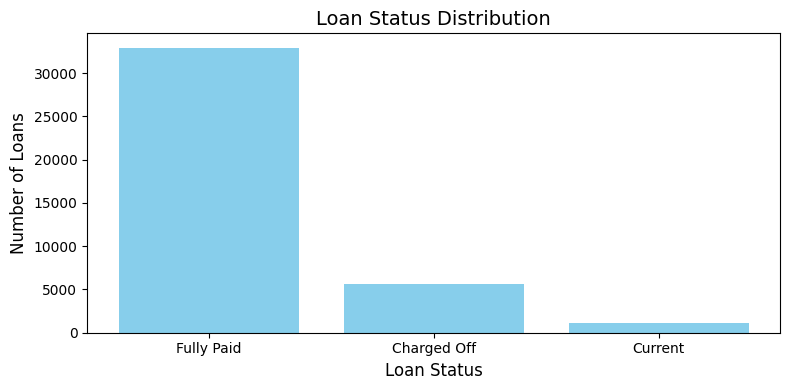

In [36]:
# Plot 1: Loan Status Distribution
plt.figure(figsize=(8, 4))
status_counts = df_clean["loan_status"].value_counts()
plt.bar(status_counts.index.astype(str), status_counts.values, color='skyblue')
plt.title("Loan Status Distribution", fontsize=14)
plt.xlabel("Loan Status", fontsize=12)
plt.ylabel("Number of Loans", fontsize=12)
plt.tight_layout()
plt.show()

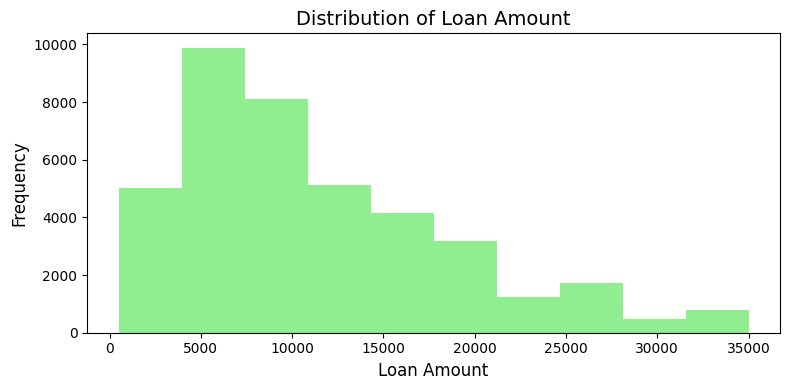

In [37]:
# Plot 2: Distribution of Loan Amount
plt.figure(figsize=(8, 4))
plt.hist(df_clean["loan_amnt"], bins=10, color='lightgreen')
plt.title("Distribution of Loan Amount", fontsize=14)
plt.xlabel("Loan Amount", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

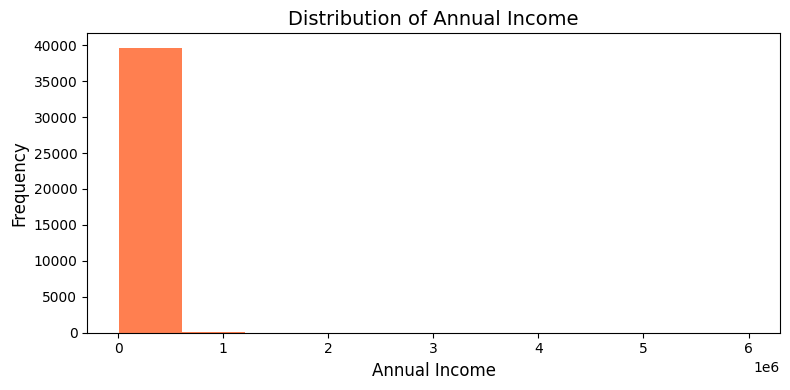

In [38]:
# Plot 3: Distribution of Annual Income
plt.figure(figsize=(8, 4))
plt.hist(df_clean["annual_inc"], bins=10, color='coral')
plt.title("Distribution of Annual Income", fontsize=14)
plt.xlabel("Annual Income", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

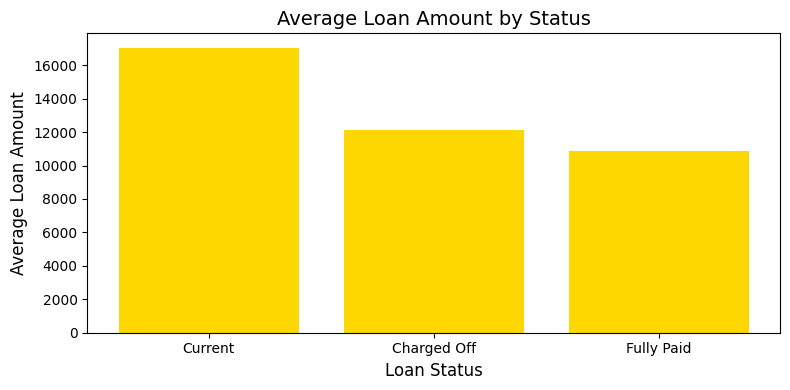

In [39]:
# Plot 4: Average Loan Amount by Status
# Calculate average loan amount from the already cleaned dataset
average_loan = df_clean.groupby("loan_status")["loan_amnt"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(average_loan.index.astype(str), average_loan.values, color='gold')
plt.title("Average Loan Amount by Status", fontsize=14)
plt.xlabel("Loan Status", fontsize=12)
plt.ylabel("Average Loan Amount", fontsize=12)
plt.tight_layout()
plt.show()

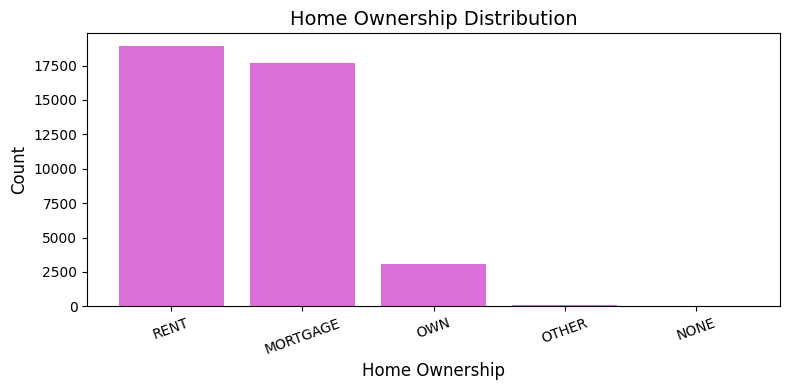

In [40]:
# Plot 5: Home Ownership Distribution
plt.figure(figsize=(8, 4))
home_counts = df_clean["home_ownership"].value_counts()
plt.bar(home_counts.index.astype(str), home_counts.values, color='orchid')
plt.title("Home Ownership Distribution", fontsize=14)
plt.xlabel("Home Ownership", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

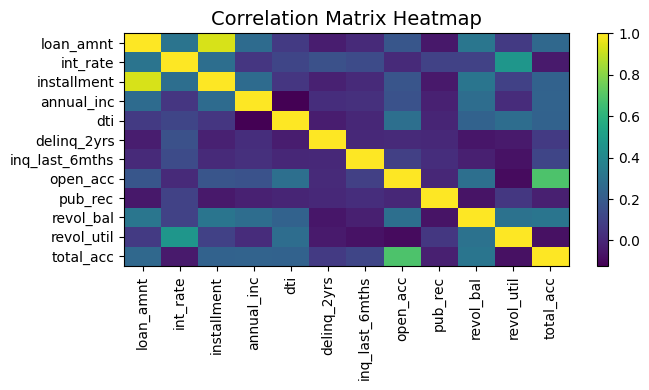

In [41]:
# Plot 6: Correlation Heatmap
# Use the numeric columns from the existing dataset
numeric_columns = [
    "loan_amnt", "int_rate", "installment", "annual_inc", "dti",
    "delinq_2yrs", "inq_last_6mths", "open_acc", "pub_rec",
    "revol_bal", "revol_util", "total_acc"
]
correlation_matrix = df_clean[numeric_columns].corr()

plt.figure(figsize=(7, 4))
plt.imshow(correlation_matrix, aspect="auto", cmap='viridis')
plt.colorbar()
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
plt.title("Correlation Matrix Heatmap", fontsize=14)
plt.tight_layout()
plt.show()

## Stage 5: Rule-Based Analysis (Prediction and Export)

In [20]:
# 6 Rule-Based Analysis (Prediction and Export)

# Define Prediction Logic
def predict_loan_status(row):
    if row["dti"] <= 20 and row["annual_inc"] >= 30000 and row["revol_util"] <= 70:
        return "Fully Paid"
    if row["dti"] >= 35 or row["revol_util"] >= 90:
        return "Charged Off"
    return "Current"

df_clean["predicted_status"] = df_clean.apply(predict_loan_status, axis=1)

# Evaluate Matching Rate
matching_rows = (df_clean["loan_status"] == df_clean["predicted_status"]).sum()
matching_rate = (matching_rows / len(df_clean)) * 100

print(f"Rule-based matching rate: {matching_rate:.2f}%")

# Save Final 20-Column Cleaned Dataset
output_file = "cleaned_loan_data.csv"
final_columns = [
    "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade",
    "emp_length", "home_ownership", "annual_inc", "verification_status",
    "purpose", "dti", "delinq_2yrs", "inq_last_6mths", "open_acc",
    "pub_rec", "revol_bal", "revol_util", "total_acc", "loan_status"
]
final_df = df_clean[final_columns].copy()
final_df.to_csv(output_file, index=False)

print(f"\nCleaned dataset containing {final_df.shape[1]} columns saved as: {output_file}")

Rule-based matching rate: 62.55%

Cleaned dataset containing 20 columns saved as: cleaned_loan_data.csv
